# 🌿 ResNet-50 — lab → ngoài đồng (lần 5)

**Vì sao thử ResNet-50?** Lần 4 (ResNet-18) đạt **64,13 % macro-F1 ngoài đồng** và **97,73 % lab**, nhưng điểm chững từ epoch 13.
Các lớp kém đều là **cặp bệnh cùng cây, vết đốm nhỏ, rất giống nhau** (cà chua: đốm vi khuẩn ↔ Septoria, sớm ↔ muộn).
Thêm dữ liệu hay chỉnh thông số không giúp nữa → cần model "mắt tinh" hơn.

| | ResNet-18 | ResNet-50 |
|---|---|---|
| Số tham số | 11 triệu | 25 triệu |
| Khối dư (residual block) | 8 khối "2 lớp 3×3" | 16 khối "nút cổ chai" 1×1 → 3×3 → 1×1 |
| Đặc trưng cuối | 512 | **2.048** |
| ImageNet top-1 | 69,8 % | 80,9 % (bộ trọng số V2) |

**Notebook chạy 2 bước liền nhau:**
```
ImageNet ──(bước 0, ảnh lab 224 px)──► resnet50_duy.pth ──(fine-tune ngoài đồng, 320 px)──► resnet50_duy_plantdoc_….pth
```
Bước 0 tự **bỏ qua** nếu Drive đã có `resnet50_duy.pth` → chạy lại notebook không phải train lab lại.

### Chạy trên Google Colab
1. **Runtime → Change runtime type → T4 GPU → Save.**
2. File `data_plantdoc_80_20.zip` đã có shortcut trong **My Drive** (như các lần trước).
3. **Runtime → Run all.** Tổng ~1–1,5 giờ (bước 0 ~25–35 phút, fine-tune ~35–45 phút). Đừng đóng tab.

## 1. Chuẩn bị: thư viện, Drive, GPU

In [1]:
import os, sys, io, json, time, copy, hashlib, zipfile, shutil, csv, threading
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps, ImageFilter, ImageEnhance
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, models, transforms
from sklearn.metrics import f1_score, confusion_matrix

DRIVE_FILE_ID = "1zVTMsqvSqe_W0TLZPQteYu6QLKXJ-ZP5"     # data_plantdoc_80_20.zip

if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")
    OUT_DIR = Path("/content/drive/MyDrive/plant-disease-ml/resnet18_runs")
    WORK = Path("/content/work")
    ZIP_CANDIDATES = [Path("/content/drive/MyDrive/data_plantdoc_80_20.zip"),
                      Path("/content/drive/MyDrive/plant-disease-ml/data_plantdoc_80_20.zip")]
    import kagglehub
    # Phiên bản 2 = đúng bộ data_v2 mà model lab đã học → dùng valid/test lab để kiểm tra "có quên không"
    LAB_DIR = Path(kagglehub.dataset_download("duydangkaggle/plantvillage-leaf-grouped-split/versions/2")) / "data_v2"
    # Ảnh lá ĐÃ XÓA NỀN lấy từ bộ PlantVillage gốc công khai (~2 GB) — chỉ tải khi bật thay nền
    get_seg_root = lambda: next(Path(kagglehub.dataset_download("abdallahalidev/plantvillage-dataset")).rglob("segmented"))
else:                                                  # máy cá nhân
    OUT_DIR = Path(os.environ.get("OUT_DIR", "../models"))
    WORK = Path(os.environ.get("WORK", "../work_plantdoc"))
    ZIP_CANDIDATES = [Path(os.environ.get("ZIP_PATH", "~/Downloads/data_plantdoc_80_20.zip")).expanduser()]
    LAB_DIR = Path(os.environ.get("LAB_DIR", "../data_v2"))
    get_seg_root = lambda: Path(os.environ.get("SEG_ROOT", "../data/plantvillage_raw/raw/segmented"))

ZIP_PATH = next((p for p in ZIP_CANDIDATES if p.exists()), None)
if ZIP_PATH is None:                                   # chưa tạo shortcut → thử tải thẳng bằng gdown
    ZIP_PATH = Path("/content/data_plantdoc_80_20.zip")
    if not ZIP_PATH.exists():
        !gdown -q --id {DRIVE_FILE_ID} -O {ZIP_PATH}
assert ZIP_PATH.exists(), "Không tìm thấy zip → làm bước 2 ở đầu notebook (Add shortcut vào My Drive)."


WORK.mkdir(parents=True, exist_ok=True); OUT_DIR.mkdir(parents=True, exist_ok=True)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if "google.colab" in sys.modules and device.type != "cuda":
    raise RuntimeError("Colab đang chạy CPU (chậm ~40 lần). Runtime → Change runtime type → T4 GPU → Save, rồi chạy lại.")
print("Zip:", ZIP_PATH, "| Lab:", LAB_DIR, "| Thiết bị:", device)

Mounted at /content/drive
Using Colab cache for faster access to the 'plantvillage-leaf-grouped-split' dataset.
/usr/local/lib/python3.13/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Zip: /content/data_plantdoc_80_20.zip | Lab: /kaggle/input/plantvillage-leaf-grouped-split/data_v2 | Thiết bị: cuda


## 2. Cấu hình — mọi "núm vặn" nằm ở đây

Mỗi lần thử cải tiến → đổi **một** dòng, chạy lại, ghi kết quả vào bảng thí nghiệm.

### Nhật ký thí nghiệm (macro-F1 trên valid)
| Lần | Thay đổi | Ngoài đồng | Lab | Nhận xét |
|---|---|---|---|---|
| 0 | Model lab, chưa fine-tune | 14,50 % | 99,34 % | lab giỏi, ngoài đồng gần như đoán mò |
| 1 | Fine-tune 12 epoch | 55,83 % | – | điểm vẫn đang tăng ở epoch cuối |
| 2 | 25 epoch | 57,67 % | – | chững ~57 %, train loss vẫn giảm → bắt đầu học thuộc |
| 3 | + CutMix/MixUp + EMA (+TTA) | 58,16 % | **46,23 %** | đường điểm mượt, nhưng **quên ảnh lab**; TTA chỉ +0,2 % |
| 4 | + trộn ảnh lab + ảnh 320 px + cân bằng lớp | **64,13 %** | **97,73 %** | hết quên; chững từ epoch 13; lớp kém = cặp bệnh giống nhau |
| 5 | **ResNet-50** (giữ nguyên công thức lần 4) | ? | ? | notebook này |

**Công thức (giữ từ lần 4) nhắm vào 3 đặc tính dữ liệu:**
1. **Quên ảnh lab** (99 → 46 %): PlantDoc chỉ có 28/38 lớp; fine-tune chỉ thấy ảnh ngoài đồng → trộn lại 40 ảnh lab/lớp ("ôn bài cũ").
2. **Vết bệnh nhỏ, giống nhau** (ngô Cercospora ↔ Northern Leaf Blight, các bệnh cà chua): thu ảnh về 224 px làm mất chi tiết → 320 px.
3. **Lệch số ảnh** (35 → 144 ảnh/lớp): lớp ít ảnh được bốc **thường xuyên hơn** khi học.

In [2]:
MODEL_NAME = "resnet50"
LAB_CKPT = OUT_DIR / f"{MODEL_NAME}_duy.pth"     # model lab (bước 0 tạo ra nếu chưa có)
LAB_EPOCHS = 3            # bước 0: ResNet-18 đạt 99,3 % ở epoch 3 → 3 epoch là đủ
LAB_LR = 1e-3
LAB_BATCH = 64

IMAGE_SIZE = 320          # Lần 4: 224 → 320. Ảnh ngoài đồng có nhiều lá, vết bệnh nhỏ → thu về 224 thì mất chi tiết.
                          # Nếu đưa model này vào backend: sửa IMAGE_SIZE = 320 ở backend/service.py cho khớp.
BATCH_SIZE = 32           # ResNet-50 ở 320 px + AMP vẫn vừa 16 GB của T4. Bộ ngoài đồng nhỏ (~2.000 ảnh) → batch nhỏ, nhiều bước cập nhật hơn
NUM_WORKERS = os.cpu_count() or 2

EPOCHS_HEAD = 3           # giai đoạn A: chỉ dạy lại lớp cuối (fc)
LR_HEAD = 1e-3
EPOCHS_FULL = 20          # giai đoạn B. Lần 2–3: điểm chững từ epoch ~16 → 20 là đủ
LR_FULL = 1e-4            # nhỏ hơn 10 lần lúc train từ ImageNet → không "phá" kiến thức cũ

MIX_LAB_PER_CLASS = 40    # Lần 4: trộn 40 ảnh lab/lớp (38 lớp) vào train → model "ôn bài cũ", không quên ảnh lab. 0 = tắt
BALANCED = True           # Lần 4: lớp ít ảnh được bốc thường xuyên hơn lớp nhiều ảnh (chỉ trong phần ảnh ngoài đồng)
BG_SWAP_PER_CLASS = 0     # >0: thêm N ảnh/lớp "lá lab dán lên nền ngoài trời" (cần tải thêm ~2 GB). 0 = chỉ dùng dữ liệu Drive

# --- Lần 3: chống "học thuộc" + làm mượt (chi tiết ở mục 6) ---
MIX_PROB = 0.5            # mỗi batch ở giai đoạn B: 50% bị ghép ảnh (CutMix / MixUp). 0 = tắt
EMA_DECAY = 0.995         # giữ thêm 1 bản model "trung bình trượt" các trọng số gần đây. 0 = tắt
USE_TTA = False           # Lần 3: TTA chỉ +0,2 % → tắt cho nhanh. Khi CHẤM: đoán trên ảnh gốc + lật ngang + lật dọc rồi lấy trung bình
NEAR_DUP_BITS = 2         # 2 ảnh có "dấu vân tay" (dHash) lệch ≤ 2 bit coi là cùng một ảnh
torch.manual_seed(42); rng = np.random.default_rng(42)
RUN_NAME = (f"{MODEL_NAME}_duy_plantdoc_s{IMAGE_SIZE}_e{EPOCHS_FULL}_bg{BG_SWAP_PER_CLASS}_mix{MIX_LAB_PER_CLASS}"
            f"_cm{int(MIX_PROB*100)}_ema{int(EMA_DECAY > 0)}_bal{int(BALANCED)}")   # mỗi cấu hình một tên → không ghi đè lần chạy cũ
print("Lần chạy:", RUN_NAME)

Lần chạy: resnet50_duy_plantdoc_s320_e20_bg0_mix40_cm50_ema1_bal1


## Bước 0 — ResNet-50 học ảnh lab (PlantVillage `data_v2`)

Giống hệt notebook 04 nhưng đổi sang ResNet-50: bắt đầu từ trọng số ImageNet, thay lớp cuối 1.000 → 38 lớp,
học 3 epoch trên ảnh lab 224 px. Đây là "kiến thức nền" về 38 bệnh trước khi ra đồng.

In [3]:
if LAB_CKPT.exists():
    print(f"Đã có {LAB_CKPT.name} → bỏ qua bước 0.")
else:
    MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
    tf_tr = transforms.Compose([transforms.Resize((224, 224)), transforms.RandomHorizontalFlip(),
                                transforms.RandomVerticalFlip(), transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
    tf_ev = transforms.Compose([transforms.Resize((224, 224)), transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
    lab_tr = datasets.ImageFolder(LAB_DIR / "train", tf_tr)
    lab_va = datasets.ImageFolder(LAB_DIR / "valid", tf_ev)
    dl_tr = DataLoader(lab_tr, LAB_BATCH, shuffle=True, num_workers=NUM_WORKERS, pin_memory=True)
    dl_va = DataLoader(lab_va, 128, num_workers=NUM_WORKERS, pin_memory=True)
    m = getattr(models, MODEL_NAME)(weights="IMAGENET1K_V2")
    m.fc = nn.Linear(m.fc.in_features, len(lab_tr.classes)); m = m.to(device)
    print(f"{MODEL_NAME}: {sum(p.numel() for p in m.parameters()):,} tham số | train lab {len(lab_tr):,} ảnh")
    opt = torch.optim.AdamW(m.parameters(), lr=LAB_LR, weight_decay=1e-4)
    sch = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=LAB_LR, total_steps=LAB_EPOCHS * len(dl_tr))
    crit = nn.CrossEntropyLoss(label_smoothing=0.1)
    sc = torch.amp.GradScaler(enabled=device.type == "cuda")
    torch.backends.cudnn.benchmark = True
    best = -1.0
    for ep in range(1, LAB_EPOCHS + 1):
        t0 = time.time(); m.train(); tot = 0.0
        for x, y in dl_tr:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            with torch.autocast(device.type, enabled=device.type == "cuda"):
                loss = crit(m(x), y)
            opt.zero_grad(); sc.scale(loss).backward(); sc.step(opt); sc.update(); sch.step()
            tot += loss.item()
        m.eval(); ys, ps = [], []
        with torch.no_grad():
            for x, y in dl_va:
                with torch.autocast(device.type, enabled=device.type == "cuda"):
                    ps.append(m(x.to(device)).argmax(1).cpu())
                ys.append(y)
        ys, ps = torch.cat(ys).numpy(), torch.cat(ps).numpy()
        f1 = f1_score(ys, ps, average="macro")
        saved = ""
        if f1 > best:
            best = f1
            torch.save({"model_name": MODEL_NAME, "classes": lab_tr.classes, "model_state_dict": m.state_dict(),
                        "image_size": 224}, LAB_CKPT)
            saved = "  ⭐ lưu"
        print(f"[lab] epoch {ep}/{LAB_EPOCHS} | {time.time()-t0:4.0f}s | loss {tot/len(dl_tr):.3f} | "
              f"valid lab acc {(ys == ps).mean()*100:.2f}% | macro-F1 {f1*100:.2f}%{saved}")
    del m, opt, dl_tr
    if device.type == "cuda": torch.cuda.empty_cache()

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 142MB/s]


resnet50: 23,585,894 tham số | train lab 81,146 ảnh
[lab] epoch 1/3 |  591s | loss 1.034 | valid lab acc 97.32% | macro-F1 96.88%  ⭐ lưu
[lab] epoch 2/3 |  409s | loss 0.725 | valid lab acc 99.18% | macro-F1 99.00%  ⭐ lưu
[lab] epoch 3/3 |  404s | loss 0.685 | valid lab acc 99.62% | macro-F1 99.50%  ⭐ lưu


## 3. Lấy & **làm sạch** PlantDoc

Bộ zip chia sẵn `train / valid / test`, nhưng PlantDoc gốc có **ảnh trùng**:
cùng một tấm ảnh tải từ web về 2 lần, hoặc bản thu nhỏ của nhau. Kiểm tra trước đó cho thấy:

* **11** nhóm ảnh giống hệt nhau từng byte nằm ở 2 phần khác nhau,
* **13 / 236** ảnh test có "anh em sinh đôi" trong train (9 ảnh còn **khác nhãn**).

Để model không được "xem trước đề", ta **bỏ** khỏi valid/test mọi ảnh trùng hoặc gần trùng với ảnh đã học.

**dHash** = thu ảnh về 9×8 ô xám, so mỗi ô với ô bên phải (sáng hơn → 1, tối hơn → 0) → 64 bit.
Hai ảnh giống nhau (kể cả khác kích thước, nén lại) cho 64 bit gần như y hệt.

Tiện thể ta **thu nhỏ** ảnh (cạnh ngắn 288 px) để mỗi epoch đọc ảnh nhanh hơn nhiều.

In [4]:
SPLITS = ("train", "valid", "test")
CLEAN = WORK / "plantdoc_clean"

def dhash(im, n=8):
    g = np.asarray(im.convert("L").resize((n + 1, n), Image.Resampling.BILINEAR), dtype=np.int16)
    bits = (g[:, :-1] > g[:, 1:]).flatten()
    return int(sum(1 << i for i, b in enumerate(bits) if b))

def scan(zf, name):
    """Đọc 1 ảnh trong zip → (sha256, dhash, ảnh đã thu nhỏ) hoặc None nếu ảnh hỏng."""
    raw = zf.read(name)
    try:
        im = ImageOps.exif_transpose(Image.open(io.BytesIO(raw))).convert("RGB")
    except Exception:
        return None
    s = 288 / min(im.size)                          # thu nhỏ để cạnh ngắn = 288 px (ảnh nhỏ hơn thì giữ nguyên)
    small = im.resize((round(im.width * s), round(im.height * s)), Image.Resampling.LANCZOS) if s < 1 else im
    return hashlib.sha256(raw).hexdigest(), dhash(im), small

def hamming(a, b):                                   # số bit khác nhau giữa mảng a (n,) và b (m,) → (n, m)
    x = (a[:, None] ^ b[None, :]).view(np.uint8).reshape(len(a), len(b), 8)
    return np.unpackbits(x, axis=-1).sum(-1)

def build_clean(zip_path, out_dir, near=NEAR_DUP_BITS):
    zf = zipfile.ZipFile(zip_path)
    names = [n for n in zf.namelist() if not n.endswith("/") and n.count("/") >= 3]
    items = []
    for n in names:
        _, split, cls, fname = n.split("/", 3)
        if split in SPLITS:
            items.append({"zip_name": n, "split": split, "class": cls, "file": fname})
    with ThreadPoolExecutor(8) as ex:               # mỗi luồng mở zip riêng cho an toàn
        local = threading.local()
        def job(it):
            if not hasattr(local, "zf"): local.zf = zipfile.ZipFile(zip_path)
            return scan(local.zf, it["zip_name"])
        results = list(ex.map(job, items))

    kept, dropped = {s: [] for s in SPLITS}, []
    seen_sha = set()
    for split in SPLITS:                             # thứ tự quan trọng: train → valid → test
        for it, r in zip(items, results):
            if it["split"] != split: continue
            if r is None: dropped.append((it, "ảnh hỏng")); continue
            sha, dh, small = r
            if sha in seen_sha: dropped.append((it, "trùng byte")); continue
            if split != "train":                     # so với mọi ảnh đã giữ ở các phần TRƯỚC nó
                before = [k for s in SPLITS[:SPLITS.index(split)] for k in kept[s]]
                if before and hamming(np.array([dh], dtype=np.uint64),
                                      np.array([k["dhash"] for k in before], dtype=np.uint64)).min() <= near:
                    dropped.append((it, "gần trùng ảnh đã học")); continue
            seen_sha.add(sha)
            it.update(sha=sha, dhash=dh, small=small); kept[split].append(it)

    if out_dir.exists(): shutil.rmtree(out_dir)
    rows = []
    for split in SPLITS:
        for i, it in enumerate(kept[split]):
            p = out_dir / split / it["class"] / f"{i:05d}.jpg"
            p.parent.mkdir(parents=True, exist_ok=True)
            it.pop("small").save(p, quality=95)
            rows.append({"split": split, "class": it["class"], "file": str(p.relative_to(out_dir)),
                         "original": it["file"], "sha256": it["sha"]})
    with open(out_dir / "manifest.csv", "w", newline="") as f:
        w = csv.DictWriter(f, rows[0].keys()); w.writeheader(); w.writerows(rows)
    report = {s: {"zip": sum(it["split"] == s for it in items), "giữ": len(kept[s]),
                  "bỏ": sum(d[0]["split"] == s for d in dropped)} for s in SPLITS}
    reasons = {}
    for it, why in dropped: reasons[f'{it["split"]}: {why}'] = reasons.get(f'{it["split"]}: {why}', 0) + 1
    json.dump({"report": report, "reasons": reasons}, open(out_dir / "clean_report.json", "w"),
              ensure_ascii=False, indent=2)
    return report, reasons

t0 = time.time()
report, reasons = build_clean(ZIP_PATH, CLEAN)
print(f"Làm sạch xong sau {time.time()-t0:.0f}s")
for s, r in report.items(): print(f"  {s:5s}: zip {r['zip']:5d} → giữ {r['giữ']:5d} (bỏ {r['bỏ']})")
for k, v in reasons.items(): print(f"    - {k}: {v}")

Làm sạch xong sau 111s
  train: zip  1874 → giữ  1873 (bỏ 1)
  valid: zip   468 → giữ   448 (bỏ 20)
  test : zip   236 → giữ   221 (bỏ 15)
    - train: trùng byte: 1
    - valid: gần trùng ảnh đã học: 20
    - test: trùng byte: 11
    - test: gần trùng ảnh đã học: 4


## 4. Dataset: gán nhãn theo **tên lớp** của 38 lớp lab

PlantDoc chỉ có ~28 lớp. Nếu dùng `ImageFolder` thẳng, nó sẽ đánh số 0…27 → **lệch** với 38 lớp của model.
Nên ta tra số thứ tự theo **tên thư mục** trong danh sách 38 lớp đã lưu cùng model.

**Biến đổi ảnh khi học (augmentation) mạnh hơn notebook 04** vì ảnh ngoài đồng rất đa dạng và bộ dữ liệu nhỏ:
cắt ngẫu nhiên một phần ảnh, xoay, đổi sáng/tương phản/màu → model không học thuộc lòng từng tấm.

In [5]:
lab_ckpt = torch.load(LAB_CKPT, map_location="cpu")
CLASSES = lab_ckpt["classes"]; NUM_CLASSES = len(CLASSES)
CLS2IDX = {c: i for i, c in enumerate(CLASSES)}
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMAGE_SIZE, scale=(0.5, 1.0)),
    transforms.RandomHorizontalFlip(), transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(0.3, 0.3, 0.3, 0.03),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD),
])
eval_tf = transforms.Compose([                      # giống hệt backend
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD),
])

class ByName(Dataset):
    """Đọc thư mục <lớp>/<ảnh>, đổi tên lớp → số thứ tự trong 38 lớp."""
    def __init__(self, root, tf):
        self.samples = [(p, CLS2IDX[p.parent.name]) for p in sorted(Path(root).glob("*/*"))]
        unknown = {p.parent.name for p in Path(root).glob("*/*")} - set(CLS2IDX)
        assert not unknown, f"Lớp không có trong 38 lớp: {unknown}"
        self.tf = tf
    def __len__(self): return len(self.samples)
    def __getitem__(self, i):
        p, y = self.samples[i]
        return self.tf(Image.open(p).convert("RGB")), y

pd_train = ByName(CLEAN / "train", train_tf)
pd_valid = ByName(CLEAN / "valid", eval_tf)
lab_valid = datasets.ImageFolder(LAB_DIR / "valid", eval_tf)
assert lab_valid.classes == CLASSES

train_set = pd_train
if MIX_LAB_PER_CLASS > 0:                            # trộn thêm ít ảnh lab để chống quên
    lab_train = datasets.ImageFolder(LAB_DIR / "train", train_tf)
    targets = np.array(lab_train.targets)
    pick = np.concatenate([rng.choice(np.where(targets == c)[0], MIX_LAB_PER_CLASS, replace=False)
                           for c in range(NUM_CLASSES)])
    train_set = torch.utils.data.ConcatDataset([pd_train, torch.utils.data.Subset(lab_train, pick.tolist())])

def show(t): return np.clip(t.permute(1, 2, 0).numpy() * STD + MEAN, 0, 1)
loader = lambda ds, shuffle=False: DataLoader(ds, BATCH_SIZE if shuffle else 128, shuffle=shuffle,
                                              num_workers=NUM_WORKERS, pin_memory=device.type == "cuda")
def make_train_loader(ds):
    if not BALANCED:
        return loader(ds, True)
    # Trọng số bốc ảnh: ảnh ngoài đồng của lớp có n ảnh → 1/n (lớp nào cũng được bốc ~ngang nhau);
    # phần ảnh lab giữ trọng số 1 (đã đều 40 ảnh/lớp). Hai phần giữ nguyên tỉ lệ tổng như ban đầu.
    labels = [y for _, y in pd_train.samples]
    cnt = np.bincount(labels, minlength=NUM_CLASSES)
    w_pd = np.array([1.0 / cnt[y] for y in labels]); w_pd *= len(pd_train) / w_pd.sum()
    w = np.concatenate([w_pd, np.ones(len(ds) - len(pd_train))])
    sampler = torch.utils.data.WeightedRandomSampler(torch.as_tensor(w, dtype=torch.double), len(ds), replacement=True)
    return DataLoader(ds, BATCH_SIZE, sampler=sampler, num_workers=NUM_WORKERS, pin_memory=device.type == "cuda")

train_loader, valid_loader, lab_valid_loader = make_train_loader(train_set), loader(pd_valid), loader(lab_valid)
# Bộ lab NHỎ (20 ảnh/lớp) để theo dõi "có quên không" ngay trong từng epoch (chấm cả 8.147 ảnh mỗi epoch thì quá chậm)
_lt = np.array(lab_valid.targets)
lab_small_loader = loader(torch.utils.data.Subset(lab_valid, np.concatenate(
    [rng.choice(np.where(_lt == c)[0], min(20, (_lt == c).sum()), replace=False) for c in range(NUM_CLASSES)]).tolist()))
present = sorted({y for _, y in pd_valid.samples})
print(f"Train {len(train_set):,} ảnh (PlantDoc {len(pd_train):,} + lab {len(train_set)-len(pd_train):,}) | "
      f"valid ngoài đồng {len(pd_valid):,} ảnh / {len(present)} lớp | valid lab {len(lab_valid):,} ảnh")

Train 3,393 ảnh (PlantDoc 1,873 + lab 1,520) | valid ngoài đồng 448 ảnh / 28 lớp | valid lab 8,147 ảnh


### 4b. Thay nền — dạy model **nhìn vào lá, bỏ qua nền**

Model lab học trên ảnh nền **trơn, xám**. Nó có thể đã học "mẹo": *nền kiểu này → bệnh kia*.
Ra ngoài đồng, nền là đất, cỏ, tay người, lá khác → mẹo hết tác dụng.

Cách chữa: lấy **lá lab đã xóa nền** (nền đen) — **chỉ những lá thuộc phần TRAIN** của `data_v2`
(tra theo `manifest.csv`), để lá ở valid/test lab không lọt vào lúc học → tách chiếc lá ra → **dán lên nền ảnh ngoài trời**
(một ảnh PlantDoc bị làm mờ thật mạnh để không còn nhìn ra vết bệnh nào) → xoay, phóng to/thu nhỏ ngẫu nhiên.

Cùng một chiếc lá bệnh xuất hiện trên **hàng chục nền khác nhau** mà nhãn không đổi
→ cách duy nhất để đoán đúng là **nhìn vào chính chiếc lá**.

In [6]:
class BgSwap(Dataset):
    # Lá lab (đã xóa nền) dán lên nền ngoài trời bị làm mờ. Mỗi lần đọc → một ảnh ghép MỚI.
    def __init__(self, seg_files, bg_paths, per_class, tf, rng):
        self.items = []
        for c in CLASSES:
            files = seg_files[c]
            pick = rng.choice(len(files), min(per_class, len(files)), replace=False)
            self.items += [(files[i], CLS2IDX[c]) for i in pick]
        self.bg_paths, self.tf = bg_paths, tf

    def leaf(self, path):
        im = Image.open(path).convert("RGB")
        mask = Image.fromarray(((np.asarray(im).max(-1) > 15) * 255).astype(np.uint8))   # nền đen → 0
        mask = (mask.filter(ImageFilter.MedianFilter(5)).filter(ImageFilter.MinFilter(5))       # bỏ hạt lẻ, gọt viền đen
                    .filter(ImageFilter.GaussianBlur(1)))                                # mép mềm
        im = ImageEnhance.Brightness(im).enhance(np.random.uniform(0.7, 1.3))           # nắng gắt / trời râm
        im.putalpha(mask)
        return im.rotate(np.random.uniform(0, 360), expand=True, resample=Image.Resampling.BILINEAR)

    def background(self, size):
        if np.random.rand() < 0.2:                                                     # đôi khi: nền màu trơn ngẫu nhiên
            return Image.new("RGB", (size, size), tuple(int(v) for v in np.random.randint(0, 256, 3)))
        bg = Image.open(self.bg_paths[np.random.randint(len(self.bg_paths))]).convert("RGB")
        bg = transforms.RandomResizedCrop(size, scale=(0.3, 1.0))(bg)
        return bg.filter(ImageFilter.GaussianBlur(np.random.uniform(6, 12)))           # mờ hẳn → không còn vết bệnh

    def __len__(self): return len(self.items)
    def __getitem__(self, i):
        path, y = self.items[i]
        canvas = self.background(IMAGE_SIZE)
        lf = self.leaf(path)
        s = np.random.uniform(0.5, 0.95) * IMAGE_SIZE / max(lf.size)                   # lá chiếm 50–95 % khung
        lf = lf.resize((max(1, round(lf.width * s)), max(1, round(lf.height * s))))
        x = np.random.randint(-lf.width // 6, IMAGE_SIZE - lf.width * 5 // 6 + 1)       # cho phép lá tràn mép một chút
        y0 = np.random.randint(-lf.height // 6, IMAGE_SIZE - lf.height * 5 // 6 + 1)
        canvas.paste(lf, (x, y0), lf)
        return self.tf(canvas), y

swap_tf = transforms.Compose([transforms.ColorJitter(0.2, 0.2, 0.2, 0.02),
                              transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
if BG_SWAP_PER_CLASS > 0:
    # Ảnh màu "<uuid>___RS_Rust 1563.JPG" (train data_v2)  ↔  ảnh xóa nền "<uuid>___RS_Rust 1563_final_masked.jpg".
    # Ưu tiên khớp CẢ tên; vài lớp ảnh màu mất phần <uuid> → khớp theo đoạn sau "___", nhưng chỉ khi đoạn đó là DUY NHẤT.
    seg_root = get_seg_root()
    seg_index = {}
    for c in CLASSES:
        full = {p.stem.removesuffix("_final_masked"): p for p in (seg_root / c).glob("*")}
        tails = {}
        for stem, p in full.items(): tails.setdefault(stem.split("___")[-1], []).append(p)
        seg_index[c] = (full, {t: ps[0] for t, ps in tails.items() if len(ps) == 1})
    seg_files = {c: [] for c in CLASSES}
    for r in csv.DictReader(open(LAB_DIR / "manifest.csv")):
        full, tail = seg_index[r["class"]]
        stem = Path(r["file"]).stem
        p = full.get(stem) or tail.get(stem.split("___")[-1])
        if r["split"] == "train" and p is not None:
            seg_files[r["class"]].append(p)
    print(f"Lá xóa nền thuộc train lab: {sum(map(len, seg_files.values())):,} ảnh")
    bg_swap = BgSwap(seg_files, [p for p, _ in pd_train.samples], BG_SWAP_PER_CLASS, swap_tf, rng)
    train_set = torch.utils.data.ConcatDataset([train_set, bg_swap])
    train_loader = make_train_loader(train_set)
    print(f"+ {len(bg_swap):,} ảnh thay nền → train tổng {len(train_set):,} ảnh")

    fig, axes = plt.subplots(2, 8, figsize=(16, 4.4))
    for ax, i in zip(axes.flat, rng.choice(len(bg_swap), 16, replace=False)):
        x, y = bg_swap[int(i)]
        ax.imshow(show(x)); ax.set_title(CLASSES[y].split("___")[1][:18], fontsize=8); ax.axis("off")
    plt.tight_layout(); plt.show()

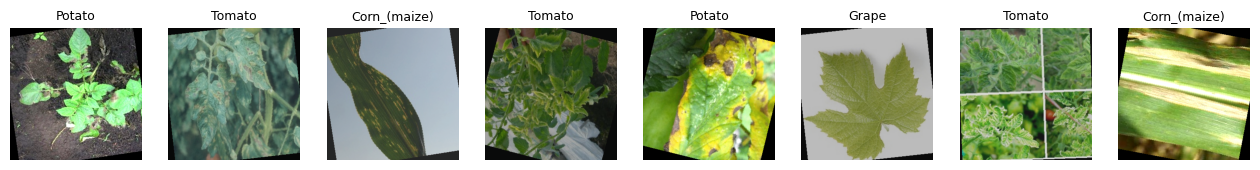

In [7]:
fig, axes = plt.subplots(1, 8, figsize=(16, 2.4))
for ax, i in zip(axes, rng.choice(len(pd_train), 8, replace=False)):
    x, y = pd_train[int(i)]
    ax.imshow(show(x)); ax.set_title(CLASSES[y].split("___")[0], fontsize=9); ax.axis("off")
plt.show()

## 5. Điểm xuất phát: model lab nhìn ảnh ngoài đồng

**Macro-F1** ở đây chỉ tính trên các lớp **có mặt** trong bộ ngoài đồng
(lớp không có ảnh nào thì không chấm được).

In [8]:
use_amp = device.type == "cuda"

def make_model(state):
    m = getattr(models, MODEL_NAME)(weights=None)
    m.fc = nn.Linear(m.fc.in_features, NUM_CLASSES)
    m.load_state_dict(state); return m.to(device)

@torch.no_grad()
def predict(m, loader, tta=False):
    m.eval(); ys, ps = [], []
    for x, y in loader:
        x = x.to(device, non_blocking=True)
        with torch.autocast(device.type, enabled=use_amp):
            prob = m(x).float().softmax(1)
            if tta:                                    # cùng chiếc lá, nhìn thêm 2 góc → trung bình 3 lần đoán
                prob += m(x.flip(3)).float().softmax(1) + m(x.flip(2)).float().softmax(1)
        ps.append(prob.argmax(1).cpu()); ys.append(y)
    return torch.cat(ys).numpy(), torch.cat(ps).numpy()

def score(y, p):
    return {"acc": float((y == p).mean()), "macro_f1": float(f1_score(y, p, labels=sorted(set(y)), average="macro"))}

lab_model = make_model(lab_ckpt["model_state_dict"])
before = {"ngoài đồng (valid)": score(*predict(lab_model, valid_loader)),
          "lab (valid)": score(*predict(lab_model, lab_valid_loader))}
if USE_TTA: before["ngoài đồng (valid, TTA)"] = score(*predict(lab_model, valid_loader, tta=True))
for k, v in before.items(): print(f"Model lab  | {k:20s}: acc {v['acc']*100:5.2f}% | macro-F1 {v['macro_f1']*100:5.2f}%")

Model lab  | ngoài đồng (valid)  : acc 20.76% | macro-F1 19.49%
Model lab  | lab (valid)         : acc 99.44% | macro-F1 99.12%


## 6. Fine-tune 2 giai đoạn

Ví dụ đời thường: một bác sĩ giỏi khám bệnh trong phòng sáng đèn, giờ chuyển ra khám ở trạm y tế xã.
Ta không bắt bác sĩ **học lại từ đầu**, chỉ cho làm quen dần.

* **Giai đoạn A — chỉ dạy lại lớp cuối (`fc`), khóa toàn bộ phần thân.**
  Phần thân đã biết "nhìn" vân lá, đốm, màu úa. Lớp cuối mới khởi đầu hơi lệch với ảnh mới;
  nếu mở khóa ngay, sai số lớn ở lớp cuối sẽ lan ngược và **phá** các bộ lọc tốt ở phần thân.
* **Giai đoạn B — mở khóa toàn bộ với learning rate rất nhỏ** (`1e-4`, lớp cuối `1e-3`).
  Phần thân được chỉnh **nhẹ** để quen với nền đất, nhiều lá, ánh nắng.

Mỗi epoch chấm trên **valid ngoài đồng**; macro-F1 tốt nhất → lưu.

### Lần 3 — vì sao thêm CutMix/MixUp và EMA?
Lần 2 (25 epoch): train loss vẫn giảm đều (1,57 → 0,95) nhưng valid **đứng ở ~57 %** từ epoch 15
→ model bắt đầu **học thuộc** ~1.900 ảnh train thay vì học quy luật chung.

* **CutMix / MixUp** — cắt một mảnh ảnh B dán vào ảnh A (hoặc chồng mờ 2 ảnh), nhãn cũng trộn theo tỉ lệ
  (vd 70 % "rỉ sắt ngô" + 30 % "lá táo khỏe"). Model không thể học thuộc từng tấm,
  và phải tìm **vết bệnh** ở bất cứ đâu trong ảnh — rất hợp với ảnh ngoài đồng nhiều lá.
* **EMA** — điểm valid đang **nhảy lên xuống** ±2 % mỗi epoch. EMA giữ một bản model là
  *trung bình trượt* của các trọng số gần đây → giống lấy điểm trung bình nhiều bài kiểm tra thay vì 1 bài → ổn định hơn.
* **TTA** (chỉ lúc chấm) — đoán 3 lần trên ảnh gốc, lật ngang, lật dọc rồi lấy trung bình.

In [9]:
model = make_model(lab_ckpt["model_state_dict"])
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
scaler = torch.amp.GradScaler(enabled=use_amp)
torch.backends.cudnn.benchmark = True
CKPT = OUT_DIR / f"{RUN_NAME}.pth"
history, best_f1 = [], -1.0

from torchvision.transforms import v2
from torch.optim.swa_utils import AveragedModel, get_ema_multi_avg_fn
mixer = v2.RandomChoice([v2.CutMix(num_classes=NUM_CLASSES), v2.MixUp(num_classes=NUM_CLASSES, alpha=0.2)])
ema = None

def run_stage(stage, epochs, optimizer, freeze_body):
    global best_f1, ema
    use_mix = not freeze_body and MIX_PROB > 0
    if not freeze_body and EMA_DECAY > 0:
        ema = AveragedModel(model, multi_avg_fn=get_ema_multi_avg_fn(EMA_DECAY), use_buffers=True)
    for p in model.parameters(): p.requires_grad = not freeze_body
    for p in model.fc.parameters(): p.requires_grad = True
    sched = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=[g["lr"] for g in optimizer.param_groups],
                                                total_steps=epochs * len(train_loader), pct_start=0.2)
    for ep in range(1, epochs + 1):
        t0 = time.time()
        model.train()
        if freeze_body: model.eval()                # thân bị khóa → giữ nguyên thống kê BatchNorm
        total = 0.0
        for x, y in train_loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            if use_mix and np.random.rand() < MIX_PROB:
                x, y = mixer(x, y)                     # y thành nhãn "trộn", vd [0.7 lớp A, 0.3 lớp B]
            with torch.autocast(device.type, enabled=use_amp):
                loss = criterion(model(x), y)
            optimizer.zero_grad(); scaler.scale(loss).backward()
            scaler.step(optimizer); scaler.update(); sched.step()
            if ema is not None and not freeze_body: ema.update_parameters(model)
            total += loss.item()
        raw = score(*predict(model, valid_loader))
        best_m = ema.module if (ema is not None and not freeze_body) else model
        s = score(*predict(best_m, valid_loader)) if best_m is not model else raw
        lab_s = score(*predict(best_m, lab_small_loader))
        history.append({"stage": stage, "epoch": len(history) + 1, "train_loss": total / len(train_loader),
                        **s, "raw_macro_f1": raw["macro_f1"], "lab_macro_f1": lab_s["macro_f1"]})
        saved = ""
        if s["macro_f1"] > best_f1:
            best_f1 = s["macro_f1"]
            torch.save({"model_name": MODEL_NAME, "classes": CLASSES, "model_state_dict": best_m.state_dict(),
                        "init_from": str(LAB_CKPT.name), "image_size": IMAGE_SIZE}, CKPT)
            saved = "  ⭐ lưu"
        extra = f" (thường {raw['macro_f1']*100:5.2f}%)" if best_m is not model else ""
        print(f"[{stage}] epoch {ep}/{epochs} | {time.time()-t0:3.0f}s | loss {history[-1]['train_loss']:.3f} | "
              f"ngoài đồng acc {s['acc']*100:5.2f}% F1 {s['macro_f1']*100:5.2f}%{extra} | lab F1 {lab_s['macro_f1']*100:5.2f}%{saved}")

run_stage("A", EPOCHS_HEAD, torch.optim.AdamW(model.fc.parameters(), lr=LR_HEAD, weight_decay=1e-4), True)
body = [p for n, p in model.named_parameters() if not n.startswith("fc.")]
run_stage("B", EPOCHS_FULL, torch.optim.AdamW([{"params": body, "lr": LR_FULL},
                                               {"params": model.fc.parameters(), "lr": LR_FULL * 10}],
                                              weight_decay=1e-4), False)
json.dump(history, open(OUT_DIR / f"{RUN_NAME}_history.json", "w"), indent=2)

[A] epoch 1/3 |  64s | loss 1.929 | ngoài đồng acc 39.06% F1 35.22% | lab F1 99.21%  ⭐ lưu
[A] epoch 2/3 |  61s | loss 1.605 | ngoài đồng acc 42.86% F1 40.38% | lab F1 99.47%  ⭐ lưu
[A] epoch 3/3 |  61s | loss 1.529 | ngoài đồng acc 41.96% F1 40.40% | lab F1 99.34%  ⭐ lưu
[B] epoch 1/20 |  72s | loss 2.009 | ngoài đồng acc 44.20% F1 41.83% (thường 39.25%) | lab F1 98.68%  ⭐ lưu
[B] epoch 2/20 |  74s | loss 1.808 | ngoài đồng acc 47.10% F1 45.32% (thường 46.68%) | lab F1 98.81%  ⭐ lưu
[B] epoch 3/20 |  72s | loss 1.621 | ngoài đồng acc 51.56% F1 49.30% (thường 57.06%) | lab F1 99.20%  ⭐ lưu
[B] epoch 4/20 |  73s | loss 1.645 | ngoài đồng acc 54.91% F1 55.19% (thường 55.76%) | lab F1 98.94%  ⭐ lưu
[B] epoch 5/20 |  73s | loss 1.512 | ngoài đồng acc 60.49% F1 59.91% (thường 62.12%) | lab F1 98.82%  ⭐ lưu
[B] epoch 6/20 |  73s | loss 1.475 | ngoài đồng acc 62.95% F1 61.75% (thường 60.93%) | lab F1 98.81%  ⭐ lưu
[B] epoch 7/20 |  72s | loss 1.415 | ngoài đồng acc 64.29% F1 62.05% (thường 66

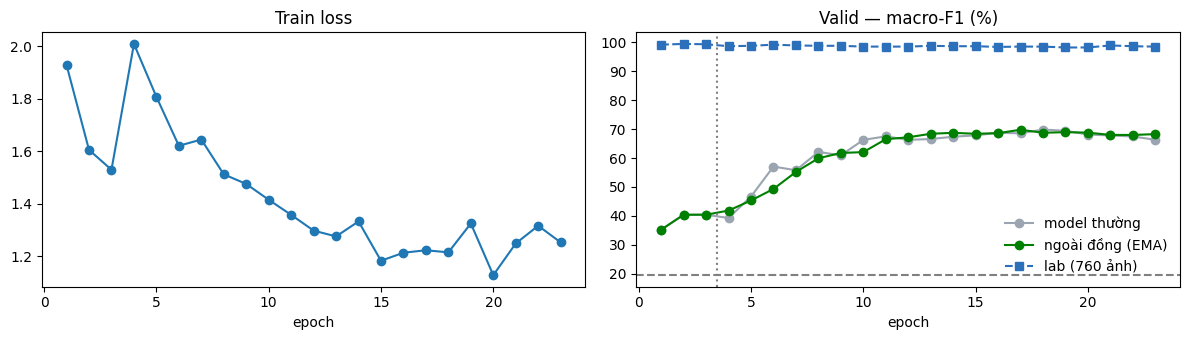

In [10]:
ep = [h["epoch"] for h in history]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.5))
a1.plot(ep, [h["train_loss"] for h in history], "o-"); a1.set_title("Train loss"); a1.set_xlabel("epoch")
a2.plot(ep, [h["raw_macro_f1"] * 100 for h in history], "o-", color="#9aa5b1", label="model thường")
a2.plot(ep, [h["macro_f1"] * 100 for h in history], "o-", color="green", label="ngoài đồng (EMA)")
a2.plot(ep, [h["lab_macro_f1"] * 100 for h in history], "s--", color="#2c6fbb", label="lab (760 ảnh)")
a2.legend(frameon=False)
a2.axhline(before["ngoài đồng (valid)"]["macro_f1"] * 100, ls="--", color="gray")
a2.axvline(EPOCHS_HEAD + 0.5, ls=":", color="gray")
a2.set_title("Valid — macro-F1 (%)"); a2.set_xlabel("epoch")
plt.tight_layout(); plt.savefig(OUT_DIR / f"{RUN_NAME}_curves.png", dpi=120); plt.show()

## 7. Trước ↔ sau fine-tune

Hai câu hỏi: ảnh ngoài đồng **tăng** bao nhiêu? ảnh lab **giảm** bao nhiêu (model có "quên" không)?

                     |  model lab |  fine-tune   (macro-F1)
ngoài đồng (valid)   |     19.49% |     69.78%
lab (valid)          |     99.12% |     98.57%


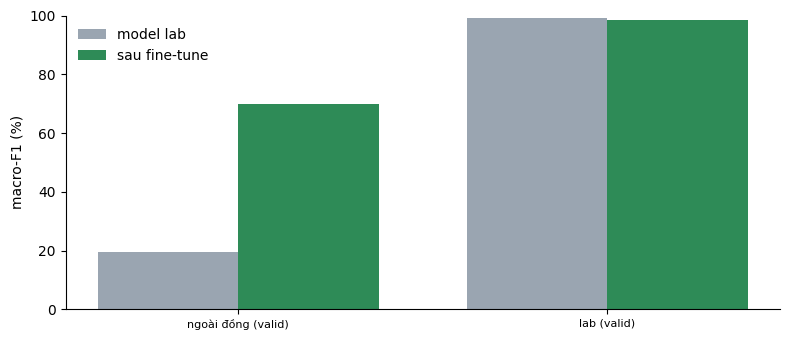

In [11]:
model.load_state_dict(torch.load(CKPT, map_location=device)["model_state_dict"])
after = {"ngoài đồng (valid)": score(*predict(model, valid_loader)),
         "lab (valid)": score(*predict(model, lab_valid_loader))}
if USE_TTA: after["ngoài đồng (valid, TTA)"] = score(*predict(model, valid_loader, tta=True))

print(f"{'':20s} | {'model lab':>10s} | {'fine-tune':>10s}   (macro-F1)")
for k in before:
    print(f"{k:20s} | {before[k]['macro_f1']*100:9.2f}% | {after[k]['macro_f1']*100:9.2f}%")
json.dump({"before": before, "after": after}, open(OUT_DIR / f"{RUN_NAME}_metrics_valid.json", "w"),
          ensure_ascii=False, indent=2)

fig, ax = plt.subplots(figsize=(8, 3.5))
xs = np.arange(len(before)); w = 0.38
ax.bar(xs - w/2, [before[k]["macro_f1"] * 100 for k in before], w, label="model lab", color="#9aa5b1")
ax.bar(xs + w/2, [after[k]["macro_f1"] * 100 for k in before], w, label="sau fine-tune", color="#2e8b57")
ax.set_xticks(xs); ax.set_xticklabels(list(before), fontsize=8); ax.set_ylim(0, 100); ax.set_ylabel("macro-F1 (%)")
ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(OUT_DIR / f"{RUN_NAME}_before_after.png", dpi=120); plt.show()

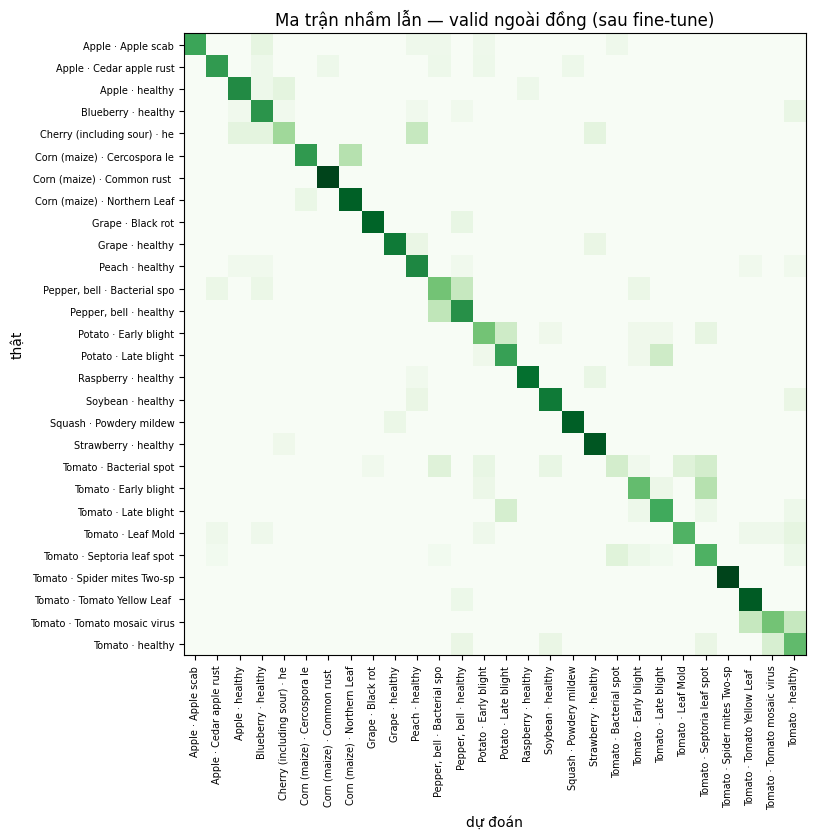

In [12]:
y, p = predict(model, valid_loader)
labels = present
cm = confusion_matrix(y, p, labels=labels, normalize="true")
short = [CLASSES[c].replace("___", " · ").replace("_", " ")[:28] for c in labels]
fig, ax = plt.subplots(figsize=(10, 8.5))
ax.imshow(cm, cmap="Greens", vmin=0, vmax=1)
ax.set_xticks(range(len(labels))); ax.set_xticklabels(short, rotation=90, fontsize=7)
ax.set_yticks(range(len(labels))); ax.set_yticklabels(short, fontsize=7)
ax.set_xlabel("dự đoán"); ax.set_ylabel("thật"); ax.set_title("Ma trận nhầm lẫn — valid ngoài đồng (sau fine-tune)")
plt.tight_layout(); plt.savefig(OUT_DIR / f"{RUN_NAME}_confusion_valid.png", dpi=120); plt.show()

### Lớp nào đang kéo điểm xuống?

Macro-F1 = **trung bình F1 của từng lớp** → vài lớp rất kém sẽ kéo cả điểm xuống.
Biết lớp nào kém (và bị nhầm sang lớp nào) mới biết nên sửa gì tiếp: thêm ảnh, gộp lớp, hay kiểm tra nhãn.

lớp                                               F1  số ảnh   hay bị nhầm thành
Tomato · Bacterial_spot                        27.6%      20   Tomato · Septoria_leaf_spot (4)
Cherry_(including_sour) · healthy              40.0%       8   Peach · healthy (2)
Tomato · healthy                               42.9%      11   Tomato · Tomato_mosaic_virus (2)
Pepper,_bell · Bacterial_spot                  44.4%      12   Pepper,_bell · healthy (3)
Tomato · Early_blight                          51.9%      13   Tomato · Septoria_leaf_spot (4)
Potato · Early_blight                          52.9%      18   Potato · Late_blight (4)
Tomato · Tomato_mosaic_virus                   53.3%       8   Tomato · Tomato_Yellow_Leaf_Curl_Virus (2)
Tomato · Septoria_leaf_spot                    58.2%      27   Tomato · Bacterial_spot (4)
Pepper,_bell · healthy                         59.3%      11   Pepper,_bell · Bacterial_spot (3)
Tomato · Late_blight                           60.6%      16   Potato · Late_b

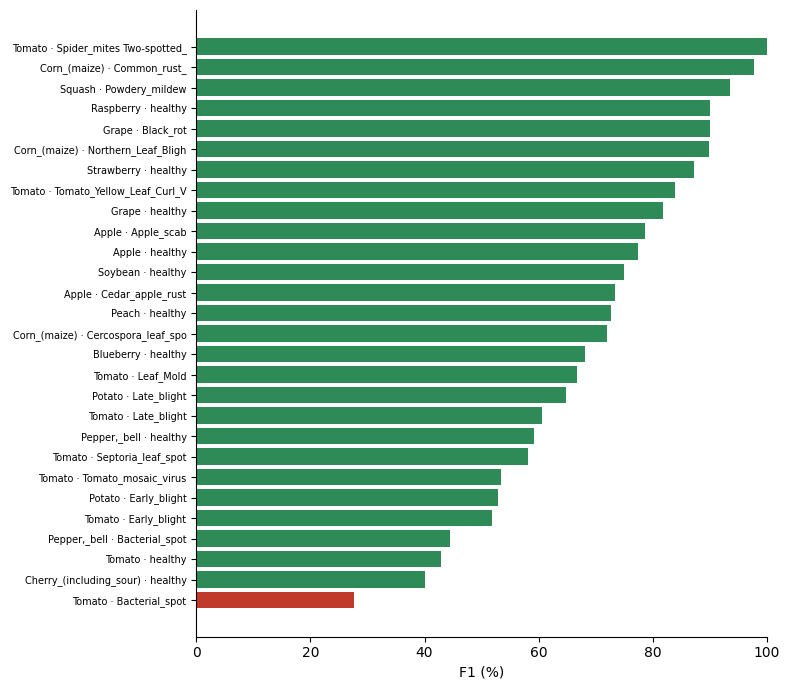

In [13]:
f1_each = f1_score(y, p, labels=present, average=None)
support = np.bincount(y, minlength=NUM_CLASSES)
order = np.argsort(f1_each)
cm_raw = confusion_matrix(y, p, labels=range(NUM_CLASSES))
print(f"{'lớp':45s} {'F1':>6s} {'số ảnh':>7s}   hay bị nhầm thành")
for k in order[:10]:
    c = present[k]
    wrong = cm_raw[c].copy(); wrong[c] = 0
    top = CLASSES[wrong.argmax()].replace("___", " · ") if wrong.sum() else "-"
    print(f"{CLASSES[c].replace('___', ' · ')[:45]:45s} {f1_each[k]*100:5.1f}% {support[c]:7d}   {top} ({wrong.max()})")

fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(range(len(order)), f1_each[order] * 100, color=["#c0392b" if v < 0.4 else "#2e8b57" for v in f1_each[order]])
ax.set_yticks(range(len(order))); ax.set_yticklabels([CLASSES[present[k]].replace("___", " · ")[:34] for k in order], fontsize=7)
ax.set_xlabel("F1 (%)"); ax.set_xlim(0, 100); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(OUT_DIR / f"{RUN_NAME}_f1_per_class.png", dpi=120); plt.show()

## 8. CAM — model nhìn vào đâu, **trước** và **sau** fine-tune?

Hàng 1: ảnh gốc · Hàng 2: model lab · Hàng 3: model sau fine-tune. Đỏ = vùng quyết định.
Model tốt phải sáng ở **vết bệnh trên lá**, không phải ở nền đất hay bầu trời.

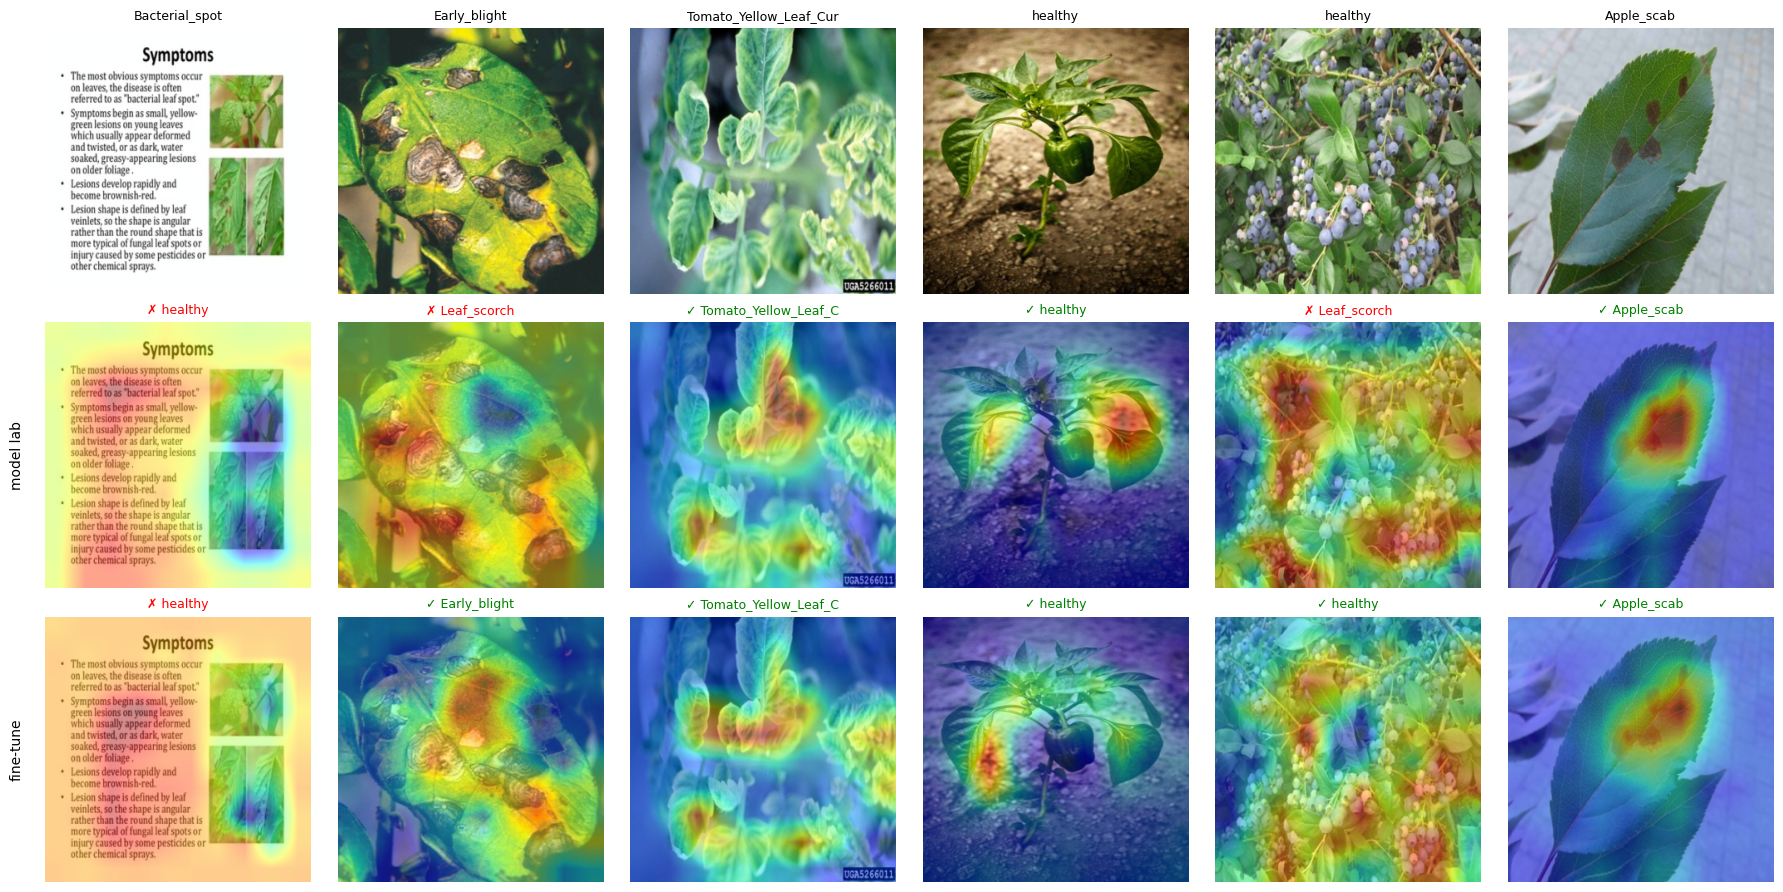

In [14]:
def cam_of(m, x):
    feats = {}
    h = m.layer4.register_forward_hook(lambda mod, i, o: feats.update(f=o))
    m.eval()
    with torch.no_grad():
        c = m(x[None].to(device)).argmax(1).item()
        cam = torch.einsum("c,chw->hw", m.fc.weight[c].float(), feats["f"][0].float())
        cam = nn.functional.interpolate(cam[None, None], size=IMAGE_SIZE, mode="bilinear")[0, 0]
        cam = ((cam - cam.min()) / (cam.max() - cam.min() + 1e-8)).cpu().numpy()
    h.remove(); return c, cam

fig, axes = plt.subplots(3, 6, figsize=(18, 9))
for k, i in enumerate(np.random.default_rng(1).choice(len(pd_valid), 6, replace=False)):
    x, y = pd_valid[int(i)]
    axes[0, k].imshow(show(x)); axes[0, k].set_title(CLASSES[y].split("___")[1][:22], fontsize=9)
    for row, m in ((1, lab_model), (2, model)):
        c, cam = cam_of(m, x)
        axes[row, k].imshow(show(x)); axes[row, k].imshow(cam, cmap="jet", alpha=0.45)
        axes[row, k].set_title(("✓ " if c == y else "✗ ") + CLASSES[c].split("___")[1][:20], fontsize=9,
                               color="green" if c == y else "red")
for a in axes.flat: a.axis("off")
axes[1, 0].text(-0.08, 0.5, "model lab", transform=axes[1, 0].transAxes, rotation=90, va="center", ha="right")
axes[2, 0].text(-0.08, 0.5, "fine-tune", transform=axes[2, 0].transAxes, rotation=90, va="center", ha="right")
plt.tight_layout(); plt.savefig(OUT_DIR / f"{RUN_NAME}_cam.png", dpi=110); plt.show()

## 9. Xuất ONNX cho backend

Vẫn 38 lớp, vẫn đầu vào 224×224 → backend dùng được ngay, không phải sửa code.

In [15]:
try:
    import onnx, onnxruntime as ort
except ImportError:
    !pip install -q onnx onnxruntime
    import onnx, onnxruntime as ort

ONNX_PATH = OUT_DIR / f"{RUN_NAME}.onnx"
model_cpu = copy.deepcopy(model).cpu().float().eval()
torch.onnx.export(model_cpu, torch.randn(1, 3, IMAGE_SIZE, IMAGE_SIZE), str(ONNX_PATH),
                  input_names=["input"], output_names=["logits"], opset_version=17,
                  dynamic_axes={"input": {0: "batch_size"}, "logits": {0: "batch_size"}}, dynamo=False)
xb = torch.stack([pd_valid[i][0] for i in range(4)])
with torch.no_grad(): ref = model_cpu(xb).numpy()
got = ort.InferenceSession(str(ONNX_PATH)).run(None, {"input": xb.numpy()})[0]
print(f"{ONNX_PATH.name}: {ONNX_PATH.stat().st_size/2**20:.1f} MB | cùng dự đoán: {(ref.argmax(1) == got.argmax(1)).all()}")

/tmp/ipykernel_1033/1513045207.py:9: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(model_cpu, torch.randn(1, 3, IMAGE_SIZE, IMAGE_SIZE), str(ONNX_PATH),


resnet50_duy_plantdoc_s320_e20_bg0_mix40_cm50_ema1_bal1.onnx: 89.9 MB | cùng dự đoán: True


## 10. TEST ngoài đồng — chấm **một lần duy nhất**

Chỉ đổi `RUN_FINAL_TEST = True` khi **đã chốt** cấu hình. Nhìn điểm test rồi quay lại chỉnh tham số
→ test thành "valid thứ hai", mất ý nghĩa *điểm thật*.
Chấm **cả hai** model trên cùng bộ test để có cặp số "trước → sau" cho buổi demo.

In [16]:
RUN_FINAL_TEST = False

if RUN_FINAL_TEST:
    pd_test = ByName(CLEAN / "test", eval_tf)
    lab_test = datasets.ImageFolder(LAB_DIR / "test", eval_tf)
    tl, ll = loader(pd_test), loader(lab_test)
    result = {name: {"ngoài đồng (test)": score(*predict(m, tl)),
                     "ngoài đồng (test, TTA)": score(*predict(m, tl, tta=True)),
                     "lab (test)": score(*predict(m, ll))}
              for name, m in (("model lab", lab_model), ("fine-tune", model))}
    json.dump(result, open(OUT_DIR / f"{RUN_NAME}_metrics_test.json", "w"), ensure_ascii=False, indent=2)
    for name, r in result.items():
        print(f"{name:10s} | " + " | ".join(f"{k}: acc {v['acc']*100:5.2f}% F1 {v['macro_f1']*100:5.2f}%" for k, v in r.items()))